# MLP 이진 분류 — 타이타닉 생존자 예측 (PyTorch)

수업 필기 `MLP_타이타닉_생존자_예측` 을 실행 가능하도록 정리 · 개선한 노트입니다.

- 📖 교재 : `딥러닝` 교재8 **p.79~85 · 90** (`nn.Linear` · `nn.Sequential` · 이진 분류 모델 · `BCEWithLogitsLoss` · Adam · 학습 루프 5단계 · 평가)
- 🔗 앞 노트 : [`gradient_descent_backprop.ipynb`](./gradient_descent_backprop.ipynb) (경사하강법 · 역전파 · 옵티마이저) / 다음 노트 : [`mlp_diabetes_iris.ipynb`](./mlp_diabetes_iris.ipynb) (다중 분류 · 회귀)
- 필기는 **학습까지만** 있고 평가가 없어서, 교재 p.85 방식의 **평가 · 비교 실험** 을 이어 붙였습니다.
- 📝 고친 부분은 그 자리에 적고 맨 아래 표로 모았습니다. 🎬 애니메이션은 [`images/`](./images/) 폴더.

In [1]:
# 한글 폰트 설정 (Windows: Malgun Gothic / macOS: AppleGothic)
import platform
import matplotlib.pyplot as plt
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

## 1. 환경 설정

In [2]:
# 필요한 라이브러리 / 모듈 / 클래스 / 함수 임포트
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
torch.manual_seed(SEED)     # 가중치 초기값 · 미니배치 순서를 매번 같게 (재현성)
np.random.seed(SEED)

In [3]:
# 연산 장치(디바이스) 설정
# torch.cuda : PyTorch 에서 NVIDIA GPU 연산과 GPU 메모리를 관리하는 모듈
# torch.cuda.is_available() 가 True 면 GPU 사용 가능 (Colab: 런타임 → 런타임 유형 변경 → GPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'사용 중인 디바이스: {device}')

사용 중인 디바이스: cpu


> **📝 고친 부분** — 쓰지 않는 `from torch.cuda import is_available` 삭제(아래에서 `torch.cuda.is_available()` 로 부름), 내용 없는 셀 `# 무료 gpu 연결` 은 주석으로 합침. 시드를 고정하지 않으면 실행할 때마다 손실 · 정확도가 조금씩 달라진다(필기의 마지막 손실 0.3090 도 다시 돌리면 다른 값) → `torch.manual_seed` 추가.

## 2. 데이터 불러오기

In [4]:
# CSV 는 이 노트북과 같은 폴더에 둔다 (Colab 이면 드라이브를 마운트한 뒤 경로만 바꾸면 됨)
df = pd.read_csv('titanic_cleaned.csv')
print(df.shape)
df.head()

(1308, 11)


,Survived,Pclass,SibSp,Parch,Fare,Age_step,Gender_female,Gender_male,Embarked_C,Embarked_Q,Embarked_S
0,0,3,1,0,7.2500,2,0,1,0,0,1
1,1,1,1,0,66.3438,3,1,0,1,0,0
2,1,3,0,0,7.9250,2,1,0,0,0,1
3,1,1,1,0,53.1000,3,1,0,0,0,1
4,0,3,0,0,8.0500,3,0,1,0,0,1


> **📝 고친 부분** — `from google.colab import drive; drive.mount(...)` 와 드라이브 경로 `/content/drive/MyDrive/sk/...` 는 Colab 밖에서 실행되지 않아서 **같은 폴더의 CSV** 로 바꿨다.

컬럼 : 정답 `Survived` (0 사망 / 1 생존) + 특성 10개 (`Pclass` 객실 등급 · `SibSp` 형제·배우자 수 · `Parch` 부모·자녀 수 · `Fare` 요금 · `Age_step` 나이 구간 · 성별 원-핫 2개 · 승선 항구 원-핫 3개).

## 3. 학습용 · 평가용 데이터 나누기 (80 : 20)

In [5]:
X_data = df.drop(columns=['Survived'])   # 문제: 정답 컬럼 제거
y_data = df['Survived']                  # 정답

# train_test_split : random_state(무작위성 고정) + stratify(정답 비율 유지)
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=0, stratify=y_data
)
print(f'학습용 {X_train.shape} · 평가용 {X_test.shape}')
print('학습용 정답 비율:', y_train.value_counts(normalize=True).round(4).to_dict())
print('평가용 정답 비율:', y_test.value_counts(normalize=True).round(4).to_dict())
print('X_train 과 y_train 의 인덱스가 같은가?', (X_train.index == y_train.index).all())

학습용 (1046, 10) · 평가용 (262, 10)
학습용 정답 비율: {0: 0.6224, 1: 0.3776}
평가용 정답 비율: {0: 0.6221, 1: 0.3779}
X_train 과 y_train 의 인덱스가 같은가? True


`stratify=y_data` 덕분에 학습용 · 평가용 모두 사망 62% · 생존 38% 로 같다. 모두 0 이라고 찍어도 정확도 **62%** — 모델은 이보다 높아야 의미가 있다.

> **📝 고친 부분** — 주석 오타 `strafity` → **`stratify`**.

## 4. 전처리 — 표준화

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # 평균 · 표준편차는 학습용으로만 계산(fit)
X_test_scaled = scaler.transform(X_test)         # 평가용은 학습용 기준으로 변환만

print('학습용 평균(≈0):', X_train_scaled.mean(axis=0).round(2))
print('학습용 표준편차(≈1):', X_train_scaled.std(axis=0).round(2))
print('평가용 평균(정확히 0 은 아님):', X_test_scaled.mean(axis=0).round(2))

학습용 평균(≈0): [ 0.  0. -0.  0. -0. -0. -0.  0.  0. -0.]
학습용 표준편차(≈1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
평가용 평균(정확히 0 은 아님): [-0.1  -0.03  0.08  0.06  0.07  0.03 -0.03  0.08  0.06 -0.11]


평가용 평균이 정확히 0 이 아닌 게 정상이다. 평가용까지 `fit` 하면 평가 데이터 정보가 학습에 새어 들어간다(데이터 누수). 필기는 이 부분을 올바르게 했다.

## 5. PyTorch 텐서로 변환 · DataLoader

In [7]:
# 자동 미분 · 역전파 · GPU 연산을 쓰려고 넘파이 배열 → PyTorch 텐서
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).to(device)   # BCE 정답은 실수(0.0 / 1.0)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).to(device)     # 평가용 정답도 준비

print(X_train_tensor.shape, y_train_tensor.shape, y_train_tensor.dtype)

# TensorDataset : 문제와 정답을 같은 인덱스끼리 한 쌍으로 묶는다 → 미니배치로 섞어도 짝이 유지됨
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

# DataLoader : 매 에포크 섞어서(shuffle) 32 개씩 꺼내 주는 도구
g = torch.Generator().manual_seed(SEED)          # 섞는 순서도 고정
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, generator=g)
print(f'미니배치 개수: {len(train_loader)} (1046 / 32 → 올림)')

torch.Size([1046, 10]) torch.Size([1046]) torch.float32
미니배치 개수: 33 (1046 / 32 → 올림)


> **📝 고친 부분** — 평가용 정답 텐서 `y_test_tensor` 가 없어서 평가를 할 수 없었다 → 추가. 주석 `# print(X_test_tensor` 괄호 짝. `torch.FloatTensor(...)` 대신 `torch.tensor(..., dtype=torch.float32)` (요즘 권장 방식, 결과는 같음).

## 6. MLP 분류 모델 (교재 p.79~81)

`nn.Linear(입력 수, 뉴런 수)` 를 `nn.Sequential` 로 순서대로 쌓는다. 이진 분류라 출력 뉴런은 **1 개**, 시그모이드는 손실 함수 안에 들어 있으므로 모델 끝에 넣지 않는다.

| 층 | 모양 | 파라미터 수 |
|---|---|---|
| 입력 10 → 은닉1 32 | W (32, 10) + b 32 | 352 |
| 은닉1 32 → 은닉2 16 | W (16, 32) + b 16 | 528 |
| 은닉2 16 → 출력 1 | W (1, 16) + b 1 | 17 |

In [8]:
input_dim = X_train_tensor.shape[1]       # 입력 특성 수 = 10

def make_model(sigmoid_at_end=False):
    layers = [
        nn.Linear(input_dim, 32),   # [입력층 → 은닉층1] 입력 10 개, 인공 뉴런 32 개
        nn.ReLU(),                  # 활성화 함수: 음수 → 0 (비선형)
        nn.Linear(32, 16),          # [은닉층1 → 은닉층2] 입력 32 개, 인공 뉴런 16 개
        nn.ReLU(),
        nn.Linear(16, 1),           # [은닉층2 → 출력층] 출력 뉴런 1 개 (점수 = logit)
    ]
    if sigmoid_at_end:              # 11절 '잘못된 예' 실험용
        layers.append(nn.Sigmoid())
    return nn.Sequential(*layers).to(device)

torch.manual_seed(SEED)
binary_model = make_model()
print(binary_model)
print('학습할 파라미터 수:', sum(p.numel() for p in binary_model.parameters()))

Sequential(
  (0): Linear(in_features=10, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)
학습할 파라미터 수: 897


> **📝 고친 부분** — 주석 `nn.Sequential 클래수` → **클래스**.

## 7. 손실 함수 · 최적화 알고리즘 (교재 p.83)

In [9]:
# BCEWithLogitsLoss = 시그모이드 + 이진 교차 엔트로피(BCE)
# 모델 출력(logit)을 그대로 넣으면 안에서 시그모이드를 씌우고 BCE 를 계산한다 (수치적으로 더 안정적)
criterion = nn.BCEWithLogitsLoss()

# Adam : Momentum(관성) + 가중치별 보폭 조절, 학습 대상은 모델의 모든 가중치 · 편향
# lr 기본값은 0.001 인데, 여기서는 필기대로 0.005 를 쓴다
optimizer = optim.Adam(params=binary_model.parameters(), lr=0.005)

> **📝 고친 부분** — 주석 `hyperparamter` → **hyperparameter**, `lr(학습)` → **lr(학습률)**. 그리고 `params` 는 학습으로 찾는 값(파라미터)이라 하이퍼파라미터가 아니다 — 사람이 정하는 **하이퍼파라미터는 lr** 이다.

## 8. 모델 학습 — 5 단계 (교재 p.84)

① 기울기 초기화 → ② 순전파 → ③ 손실 → ④ 역전파 → ⑤ 가중치 갱신. 필기 코드에 **매 에포크 평가용 손실 · 정확도 기록** 만 더했다(그래프 · 애니메이션용).

In [10]:
@torch.no_grad()
def evaluate(model, X, y):
    """평가 모드로 손실과 정확도 계산 (기울기 계산 없음)"""
    model.eval()
    logits = model(X)
    loss = criterion(logits, y.unsqueeze(1)).item()
    acc = ((logits > 0).float().squeeze(1) == y).float().mean().item()   # logit > 0 ⇔ 확률 > 0.5
    return loss, acc

epochs = 50
history = []                                   # 에포크마다 (학습 손실, 평가 손실, 학습 정확도, 평가 정확도)

for epoch in range(epochs):
    binary_model.train()                       # 훈련 모드 (평가 후 다시 켜야 해서 루프 안으로)
    epoch_loss = 0.0
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()                              # ① 이전 기울기 삭제
        outputs = binary_model(batch_x)                    # ② 순전파: 출력 뉴런의 입력 신호 총합(logit), (32, 1)
        loss = criterion(outputs, batch_y.unsqueeze(1))    # ③ 손실: 정답 (32,) → (32, 1) 로 모양 맞춤
        loss.backward()                                    # ④ 역전파: 가중치별 기울기 계산
        optimizer.step()                                   # ⑤ 가중치 · 편향 갱신
        epoch_loss += loss.item()                          # 텐서 → 파이썬 숫자

    history.append(evaluate(binary_model, X_train_tensor, y_train_tensor)
                   + evaluate(binary_model, X_test_tensor, y_test_tensor))
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f'Epoch [{epoch + 1}/{epochs}]  미니배치 평균 BCE: {epoch_loss / len(train_loader):.4f}'
              f'  | 평가용 BCE: {history[-1][2]:.4f}  평가용 정확도: {history[-1][3]:.4f}')

history = np.array(history)[:, [0, 2, 1, 3]]   # 열 순서: 학습 손실, 평가 손실, 학습 정확도, 평가 정확도

Epoch [1/50]  미니배치 평균 BCE: 0.5520  | 평가용 BCE: 0.3815  평가용 정확도: 0.8588
Epoch [10/50]  미니배치 평균 BCE: 0.3440  | 평가용 BCE: 0.3542  평가용 정확도: 0.8588


Epoch [20/50]  미니배치 평균 BCE: 0.3323  | 평가용 BCE: 0.3462  평가용 정확도: 0.8702
Epoch [30/50]  미니배치 평균 BCE: 0.3275  | 평가용 BCE: 0.3427  평가용 정확도: 0.8740


Epoch [40/50]  미니배치 평균 BCE: 0.3172  | 평가용 BCE: 0.3429  평가용 정확도: 0.8817
Epoch [50/50]  미니배치 평균 BCE: 0.3027  | 평가용 BCE: 0.3421  평가용 정확도: 0.8779


> **📝 고친 부분** — `binary_model.train()` 을 루프 밖에서 한 번만 부르면, 중간에 `eval()` 로 평가한 뒤 다시 훈련 모드로 돌아오지 않는다. 지금 모델엔 Dropout · BatchNorm 이 없어 결과는 같지만, 습관적으로 **에포크마다 `train()`** 을 부르는 게 안전하다.

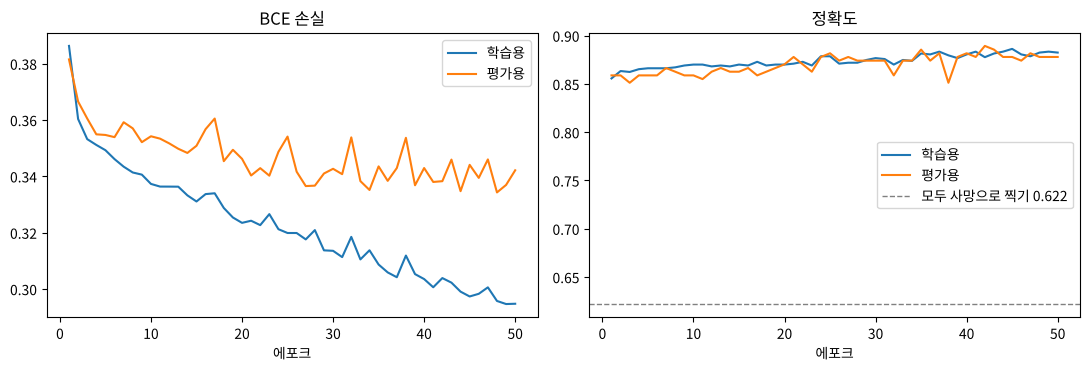

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ep = np.arange(1, epochs + 1)
axes[0].plot(ep, history[:, 0], label='학습용'); axes[0].plot(ep, history[:, 1], label='평가용')
axes[0].set(title='BCE 손실', xlabel='에포크'); axes[0].legend()
axes[1].plot(ep, history[:, 2], label='학습용'); axes[1].plot(ep, history[:, 3], label='평가용')
axes[1].axhline(0.622, color='gray', ls='--', lw=1, label='모두 사망으로 찍기 0.622')
axes[1].set(title='정확도', xlabel='에포크'); axes[1].legend()
plt.tight_layout(); plt.show()

![타이타닉 학습 애니메이션](./images/anim_04_titanic_training.gif)

## 9. 모델 평가 (교재 p.85)

logit → `torch.sigmoid` 로 확률 → **0.5 이상이면 1(생존)**.

In [12]:
binary_model.eval()                      # 평가 / 추론 모드
with torch.no_grad():                    # 평가에서는 미분 계산을 꺼서 메모리 · 연산 절약
    test_logits = binary_model(X_test_tensor)
    probs = torch.sigmoid(test_logits)                     # logit → 생존 확률
    predictions = (probs >= 0.5).int().cpu().numpy().ravel()   # GPU 텐서면 .cpu() 를 거쳐야 numpy 로 바뀜

acc = accuracy_score(y_test, predictions)
print(f'평가 정확도: {acc * 100:.2f}%')
print('처음 5 명의 생존 확률:', probs[:5].cpu().numpy().ravel().round(3), '→ 예측', predictions[:5], ' 정답', y_test.values[:5])

cm = confusion_matrix(y_test, predictions)
print('혼동 행렬 [[사망→사망, 사망→생존], [생존→사망, 생존→생존]]')
print(cm)

평가 정확도: 87.79%
처음 5 명의 생존 확률: [0.926 0.072 0.045 0.026 0.175] → 예측 [1 0 0 0 0]  정답 [0 0 0 0 1]
혼동 행렬 [[사망→사망, 사망→생존], [생존→사망, 생존→생존]]
[[151  12]
 [ 20  79]]


> **📝 고친 부분** — 교재 p.85 `(probs >= 0.5).int().numpy()` 는 GPU 에서 돌리면 `can't convert cuda tensor to numpy` 에러가 난다 → **`.cpu()`** 를 넣었다. 또 결과 모양이 (N, 1) 이라 `.ravel()` 로 1차원으로 폈다.

## 10. 비교 실험

### 10-1. 기준 모델 — 로지스틱 회귀 (은닉층 없는 퍼셉트론 1개 + 시그모이드)

In [13]:
logreg = LogisticRegression(max_iter=1000).fit(X_train_scaled, y_train)
print(f'로지스틱 회귀  학습 {logreg.score(X_train_scaled, y_train):.4f} · 평가 {logreg.score(X_test_scaled, y_test):.4f}')
print(f'MLP (50 에포크) 학습 {history[-1, 2]:.4f} · 평가 {history[-1, 3]:.4f}')

로지스틱 회귀  학습 0.8537 · 평가 0.8588
MLP (50 에포크) 학습 0.8824 · 평가 0.8779


### 10-2. 학습률 · 배치 크기 · 에포크 바꿔 보기

같은 시드, 같은 모델 구조로 조건만 바꾼다.

In [14]:
def train_model(lr=0.005, batch_size=32, epochs=50, sigmoid_at_end=False, loss_fn=None):
    """조건을 바꿔 처음부터 다시 학습 → 마지막 (학습 손실, 평가 손실, 학습 정확도, 평가 정확도) + 기록"""
    torch.manual_seed(SEED)
    model = make_model(sigmoid_at_end)
    loss_fn = loss_fn or nn.BCEWithLogitsLoss()
    opt = optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    hist = []
    for _ in range(epochs):
        model.train()
        for bx, by in loader:
            opt.zero_grad()
            loss = loss_fn(model(bx), by.unsqueeze(1))
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            out_tr, out_te = model(X_train_tensor), model(X_test_tensor)
            thr = 0.5 if sigmoid_at_end else 0.0          # 확률이면 0.5, logit 이면 0 이 기준
            hist.append([loss_fn(out_tr, y_train_tensor.unsqueeze(1)).item(),
                         loss_fn(out_te, y_test_tensor.unsqueeze(1)).item(),
                         ((out_tr > thr).float().squeeze(1) == y_train_tensor).float().mean().item(),
                         ((out_te > thr).float().squeeze(1) == y_test_tensor).float().mean().item()])
    return np.array(hist)

experiments = {
    '기본 (lr 0.005, 배치 32, 50 에포크)': dict(),
    'lr 0.001 (Adam 기본값)':             dict(lr=0.001),
    '배치 학습 (배치 1046 = 전체), 50 에포크': dict(batch_size=1046),
    '배치 학습, 500 에포크':                dict(batch_size=1046, epochs=500),
    '미니배치, 200 에포크':                 dict(epochs=200),
}
results = {}
for name, kw in experiments.items():
    h = train_model(**kw)
    results[name] = h
    best = h[:, 1].argmin()
    print(f'{name:28s} | 마지막: 학습손실 {h[-1, 0]:.3f} 평가손실 {h[-1, 1]:.3f} 평가정확도 {h[-1, 3]:.4f}'
          f' | 평가손실 최저 {h[best, 1]:.3f} @ {best + 1} 에포크')

기본 (lr 0.005, 배치 32, 50 에포크) | 마지막: 학습손실 0.295 평가손실 0.342 평가정확도 0.8779 | 평가손실 최저 0.334 @ 48 에포크


lr 0.001 (Adam 기본값)          | 마지막: 학습손실 0.332 평가손실 0.349 평가정확도 0.8626 | 평가손실 최저 0.349 @ 44 에포크


배치 학습 (배치 1046 = 전체), 50 에포크 | 마지막: 학습손실 0.349 평가손실 0.358 평가정확도 0.8626 | 평가손실 최저 0.358 @ 50 에포크


배치 학습, 500 에포크               | 마지막: 학습손실 0.230 평가손실 0.583 평가정확도 0.8550 | 평가손실 최저 0.349 @ 147 에포크


미니배치, 200 에포크                | 마지막: 학습손실 0.243 평가손실 0.444 평가정확도 0.8397 | 평가손실 최저 0.334 @ 48 에포크


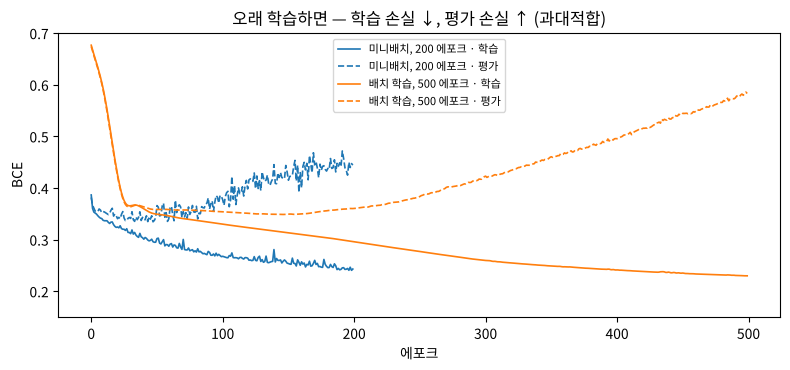

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for name in ['미니배치, 200 에포크', '배치 학습, 500 에포크']:
    h = results[name]
    line, = ax.plot(h[:, 0], lw=1.2, label=f'{name} · 학습')
    ax.plot(h[:, 1], lw=1.2, ls='--', color=line.get_color(), label=f'{name} · 평가')
ax.set(xlabel='에포크', ylabel='BCE', title='오래 학습하면 — 학습 손실 ↓, 평가 손실 ↑ (과대적합)', ylim=(0.15, 0.7))
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 10-3. 자주 하는 실수 두 가지

① 정답 모양을 (N, 1) 로 맞추지 않으면? ② 모델 끝에 `nn.Sigmoid()` 를 넣고 `BCEWithLogitsLoss` 를 쓰면(시그모이드 두 번)?

In [16]:
# ① 정답 모양 (32,) vs 출력 모양 (32, 1)
bx, by = next(iter(train_loader))
try:
    criterion(binary_model(bx), by)          # unsqueeze(1) 를 빼먹음
except ValueError as e:
    print('ValueError:', e)

# ② 시그모이드 두 번 : 출력이 이미 0~1 인데 손실 함수가 또 시그모이드를 씌운다
h_bad = train_model(sigmoid_at_end=True)
h_ok = train_model(sigmoid_at_end=True, loss_fn=nn.BCELoss())   # 시그모이드를 넣었다면 BCELoss 와 짝
print(f'Sigmoid + BCEWithLogitsLoss : 마지막 학습 손실 {h_bad[-1, 0]:.3f} · 평가 정확도 {h_bad[-1, 3]:.4f}')
print(f'Sigmoid + BCELoss           : 마지막 학습 손실 {h_ok[-1, 0]:.3f} · 평가 정확도 {h_ok[-1, 3]:.4f}')

ValueError: Target size (torch.Size([32])) must be the same as input size (torch.Size([32, 1]))


Sigmoid + BCEWithLogitsLoss : 마지막 학습 손실 0.608 · 평가 정확도 0.8664
Sigmoid + BCELoss           : 마지막 학습 손실 0.295 · 평가 정확도 0.8779


결과 해석
- **로지스틱 회귀 0.8588 → MLP 0.8779** : 은닉층 두 개가 비선형 조합(예: '3등실이면서 남자')을 잡아 평가 정확도가 약 2%p 올랐다. 생존자 99 명 중 20 명을 사망으로 놓친 것이 가장 큰 오류.
- **lr 0.001** 은 50 에포크로는 덜 내려가서(학습 손실 0.332) 0.8626. Adam 기본값이 항상 최선은 아니다.
- **배치 학습 50 에포크** 는 업데이트가 50 번뿐(미니배치는 33 × 50 = 1650 번)이라 학습 손실 0.349 로 덜 학습됐다. 에포크를 500 으로 늘리면 학습 손실 0.230 까지 내려가지만 평가 손실은 147 에포크(0.349)부터 다시 올라 0.583 이 됐다.
- **미니배치 200 에포크** 도 평가 손실이 48 에포크(0.334)에서 가장 낮고 이후 0.444 까지 올라 평가 정확도 0.8397 — **과대적합**. 50 에포크 근처에서 멈춘 필기의 선택이 좋았다. (다음 수업 주제 후보: 검증 데이터 · 조기 종료)
- 실수 ① : `unsqueeze(1)` 를 빼면 `Target size (32) must be the same as input size (32, 1)` 에러.
- 실수 ② : 시그모이드를 두 번 씌우면 출력이 0~1 이 된 뒤 다시 σ 를 거쳐 **0.27~0.73** 에 갇힌다. 그래서 손실이 0.608 아래로 내려가지 못한다. 확률 순서는 유지되어 정확도(0.8664)는 크게 안 떨어지지만 확률 값은 믿을 수 없다. 모델 끝에 `Sigmoid` 를 넣었다면 손실은 **`BCELoss`** 와 짝 — 이때 결과(0.295 · 0.8779)는 기본 모델과 똑같다.

## 📝 고친 부분 정리

| 위치 | 원래 | 고친 내용 |
|---|---|---|
| 필기 import | `from torch.cuda import is_available` (안 씀) | 삭제 |
| 필기 | 빈 셀 `# 무료 gpu 연결` | 디바이스 셀 주석으로 합침 |
| 필기 | `drive.mount` · 드라이브 경로 | 같은 폴더 CSV |
| 필기 | 시드 없음 | `torch.manual_seed` · DataLoader `generator` 로 재현 가능 |
| 필기 주석 | `strafity` · `클래수` · `hyperparamter` · `lr(학습)` | stratify · 클래스 · hyperparameter · lr(학습률) |
| 필기 주석 | `params` 가 하이퍼파라미터 | params 는 학습되는 **파라미터**, 하이퍼파라미터는 lr |
| 필기 | `y_test` 텐서 · 평가 없음 | 평가용 텐서 + 교재 p.85 평가 + 혼동 행렬 + 에포크별 기록 |
| 필기 | `train()` 을 루프 밖 한 번 | 에포크마다 `train()` / `eval()` |
| 교재 p.85 | `.int().numpy()` | GPU 대비 `.cpu()`, (N,1) → `.ravel()` |